# 02 Beats: PPG beats, device IBI and ECG

Runs on the 3 ECG people (S022, S035, S042). Functions in `src/beats.py` and `src/preprocess.py`.

The detector is tuned on S042 only; S022 and S035 are reported, never tuned on (VALIDATION_PLAN section 8).

In [1]:
import os
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src")); sys.path.insert(0, str(PROJECT / "qc"))
from qc_funcs import load_wristband
from preprocess import find_wristband_files, find_scoring_offset, make_epochs, filter_bvp, STAGES_5
from beats import (detect_beats, ecg_rpeaks, clean_intervals, rmssd, device_beats_from_ibi,
                   compare_to_device_ibi, compare_to_ecg, match_beats, timeline_lag)
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
D100 = DATA_ROOT / "physionet.org/files/dreamt/2.2.0/data_100Hz"
FIG_DIR = PROJECT / "notebooks" / "figs"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 8})
files = find_wristband_files(DATA_ROOT)
SUBJECTS = ["S042", "S022", "S035"]
DETECTOR = "msptdfast"

## Step 1: load, check both files share one time zero, detect beats

In [2]:
S = {}
for s in SUBJECTS:
    _, w = load_wristband(files[s])
    p = pd.read_csv(D100 / f"{s}_PSG_df.csv", usecols=["TIMESTAMP", "ECG", "BVP"])
    t64, t100 = w.TIMESTAMP.to_numpy(), p.TIMESTAMP.to_numpy()
    mid = 0.5 * (max(t64[0], t100[0]) + min(t64[-1], t100[-1]))
    lag, r = timeline_lag(w.BVP.to_numpy(), t64, p.BVP.to_numpy(), t100, t_start=mid)
    stage = w.Sleep_Stage.astype(str).to_numpy()
    ep = make_epochs(stage, offset=find_scoring_offset(stage)["offset"])
    f = filter_bvp(w.BVP.to_numpy())
    pk, pt = detect_beats(f, method=DETECTOR)
    pt = pt + t64[0]
    ri, rt = ecg_rpeaks(p.ECG.to_numpy())
    rt = rt + t100[0]
    dev = device_beats_from_ibi(w.IBI.to_numpy(), t64)
    S[s] = dict(w=w, p=p, t64=t64, t100=t100, f=f, pt=pt, rt=rt, dev=dev, ep=ep, stage=stage)
    print(f"{s}: 64Hz {t64[0]:.0f}-{t64[-1]:.0f}s, 100Hz {t100[0]:.0f}-{t100[-1]:.0f}s, "
          f"BVP lag {lag:+.2f}s (r={r:.2f}); PPG beats {len(pt)}, ECG beats {len(rt)}, device beats {len(dev)}", flush=True)

S042: 64Hz 0-31800s, 100Hz 30-23220s, BVP lag -4.11s (r=0.04); PPG beats 43254, ECG beats 31931, device beats 33626
S022: 64Hz 0-33105s, 100Hz 5490-30960s, BVP lag +0.19s (r=0.07); PPG beats 34522, ECG beats 23055, device beats 7717
S035: 64Hz 0-32101s, 100Hz 11130-32101s, BVP lag -0.64s (r=0.04); PPG beats 38477, ECG beats 24069, device beats 23364


## Step 2: clean intervals, compare with the device and with ECG (agreement only)

Restricted to scored sleep epochs that both files cover.

In [3]:
def scored_mask(times, d):
    ep = d["ep"][d["ep"].keep]
    starts = d["t64"][ep.start_sample.to_numpy()]
    lo, hi = d["t100"][0], d["t100"][-1]
    idx = np.searchsorted(starts, times, side="right") - 1
    ok = (idx >= 0) & (times < starts[np.clip(idx, 0, None)] + 30)
    return ok & (times >= lo) & (times <= hi)

rows = []
for s, d in S.items():
    pt = d["pt"][scored_mask(d["pt"], d)]
    rt = d["rt"][scored_mask(d["rt"], d)]
    dv = d["dev"][scored_mask(d["dev"], d)]
    ci_p, ci_e = clean_intervals(pt), clean_intervals(rt)
    d.update(ci_p=ci_p, ci_e=ci_e)
    cd = compare_to_device_ibi(pt, dv)
    rows.append({"subject": s, "ppg_beats": len(pt), "ecg_beats": len(rt), "device_beats": len(dv),
                 "ppg_pct_rejected": 100 * (~ci_p.keep).mean(), "ecg_pct_rejected": 100 * (~ci_e.keep).mean(),
                 "pct_device_matched_by_ours": cd["pct_device_matched"],
                 "median_abs_ibi_diff_vs_device_ms": cd["median_abs_ibi_diff_ms"],
                 "rmssd_ppg_ms": rmssd(ci_p), "rmssd_ecg_ms": rmssd(ci_e)})
summary = pd.DataFrame(rows).set_index("subject").round(2)
print(summary.T.to_string())

subject                               S042      S022      S035
ppg_beats                         19850.00  24169.00  24309.00
ecg_beats                         20329.00  21409.00  24069.00
device_beats                      16963.00   5544.00  17619.00
ppg_pct_rejected                      0.45     16.47      2.01
ecg_pct_rejected                      0.10      1.28      0.21
pct_device_matched_by_ours            0.00      0.00      0.00
median_abs_ibi_diff_vs_device_ms       NaN       NaN       NaN
rmssd_ppg_ms                         43.72    139.08     85.84
rmssd_ecg_ms                         32.49     44.84     67.40


## Step 3: see the gap. ECG and PPG on one time axis, with the interval series below

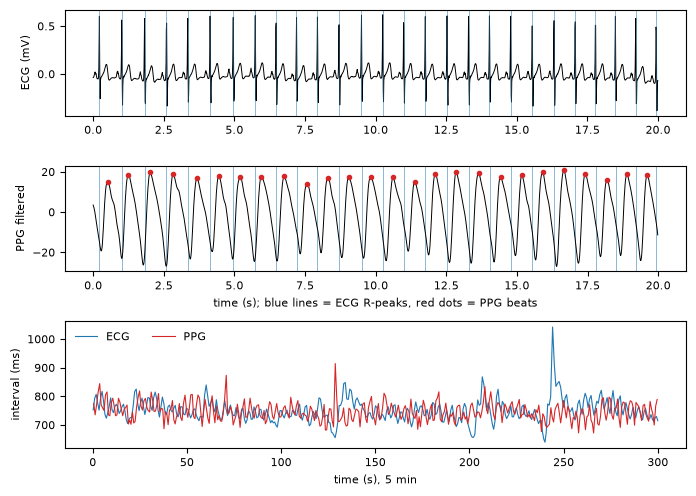

S042 N2 window at 18240s: RMSSD over 5 min, ECG 29.2 ms, PPG 37.4 ms


In [4]:
def plot_window(s, t0, dur=20, tach=300):
    d = S[s]
    fig, ax = plt.subplots(3, 1, figsize=(7, 5), gridspec_kw={"height_ratios": [1, 1, 1.2]})
    m100 = (d["t100"] >= t0) & (d["t100"] < t0 + dur)
    m64 = (d["t64"] >= t0) & (d["t64"] < t0 + dur)
    ecg = d["p"].ECG.to_numpy()[m100] * 1e3
    ax[0].plot(d["t100"][m100] - t0, ecg, color="k", lw=0.7)
    for r in d["rt"][(d["rt"] >= t0) & (d["rt"] < t0 + dur)]:
        ax[0].axvline(r - t0, color="tab:blue", lw=0.6, alpha=0.6); ax[1].axvline(r - t0, color="tab:blue", lw=0.6, alpha=0.6)
    ax[0].set_ylabel("ECG (mV)")
    ax[1].plot(d["t64"][m64] - t0, d["f"][m64], color="k", lw=0.7)
    pk = d["pt"][(d["pt"] >= t0) & (d["pt"] < t0 + dur)]
    ax[1].plot(pk - t0, np.interp(pk, d["t64"], d["f"]), "o", color="tab:red", ms=3)
    ax[1].set_ylabel("PPG filtered"); ax[1].set_xlabel("time (s); blue lines = ECG R-peaks, red dots = PPG beats")
    ce, cp = d["ci_e"], d["ci_p"]
    me = ce.keep & (ce.t >= t0) & (ce.t < t0 + tach); mp = cp.keep & (cp.t >= t0) & (cp.t < t0 + tach)
    ax[2].plot(ce.t[me] - t0, ce.ibi[me] * 1000, color="tab:blue", lw=0.8, label="ECG")
    ax[2].plot(cp.t[mp] - t0, cp.ibi[mp] * 1000, color="tab:red", lw=0.8, label="PPG")
    ax[2].set_ylabel("interval (ms)"); ax[2].set_xlabel(f"time (s), {tach // 60} min")
    ax[2].legend(frameon=False, ncol=2)
    fig.tight_layout()
    return fig, rmssd(ce[(ce.t >= t0) & (ce.t < t0 + tach)]), rmssd(cp[(cp.t >= t0) & (cp.t < t0 + tach)])

d = S["S042"]; ep = d["ep"]
n2 = ep[ep.raw == "N2"]
t0 = d["t64"][int(n2.start_sample.iloc[len(n2) // 2])]
fig, r_e, r_p = plot_window("S042", t0)
fig.savefig(FIG_DIR / "fig_s042_ecg_ppg_window.png", dpi=150); plt.show()
print(f"S042 N2 window at {t0:.0f}s: RMSSD over 5 min, ECG {r_e:.1f} ms, PPG {r_p:.1f} ms")

## Step 4: RMSSD per 5-minute window, PPG against ECG

         rmssd_ecg  rmssd_ppg  diff
subject                            
S022          43.8      140.7  97.5
S035          59.1       74.9  10.7
S042          30.7       40.6   8.5

MEDIAN PPG minus ECG RMSSD, all windows: 22.4 ms (n=196 windows)


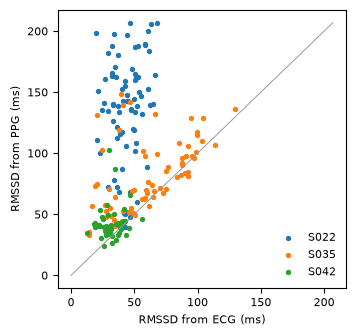

In [5]:
pairs = []
for s, d in S.items():
    ce, cp = d["ci_e"], d["ci_p"]
    lo, hi = max(ce.t.min(), cp.t.min()), min(ce.t.max(), cp.t.max())
    for w0 in np.arange(lo, hi - 300, 300):
        a = rmssd(ce[(ce.t >= w0) & (ce.t < w0 + 300)]); b = rmssd(cp[(cp.t >= w0) & (cp.t < w0 + 300)])
        if np.isfinite(a) and np.isfinite(b):
            pairs.append({"subject": s, "w0": w0, "rmssd_ecg": a, "rmssd_ppg": b})
pairs = pd.DataFrame(pairs)
pairs["diff"] = pairs.rmssd_ppg - pairs.rmssd_ecg
print(pairs.groupby("subject")[["rmssd_ecg", "rmssd_ppg", "diff"]].median().round(1).to_string())
print(f"\nMEDIAN PPG minus ECG RMSSD, all windows: {pairs['diff'].median():.1f} ms (n={len(pairs)} windows)")
fig, ax = plt.subplots(figsize=(3.6, 3.4))
for s, g in pairs.groupby("subject"):
    ax.scatter(g.rmssd_ecg, g.rmssd_ppg, s=8, label=s)
m = pairs[["rmssd_ecg", "rmssd_ppg"]].max().max()
ax.plot([0, m], [0, m], color="0.6", lw=0.7)
ax.set_xlabel("RMSSD from ECG (ms)"); ax.set_ylabel("RMSSD from PPG (ms)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_rmssd_ppg_vs_ecg.png", dpi=150); plt.show()

## Step 5: score against ECG with a delay search

DELAYS must be set from a verified source (VALIDATION_PLAN section 17 item 5). Left unset on purpose.

In [6]:
DELAYS = None   # e.g. np.arange(start, stop, 0.005) once the range is chosen
if DELAYS is None:
    print("DELAYS not set: ECG scoring skipped")
else:
    tab, best = compare_to_ecg(S["S042"]["ci_p"].t, S["S042"]["ci_e"].t, DELAYS)
    print(best)

DELAYS not set: ECG scoring skipped
